Optimizarea hiperparametrilor cu Optuna

In aceasta parte cautam combinatia de hiperparametri XGBoost care da cel mai bun macro-F1. Folosim aceleasi date, acelasi encoding (one-hot) si aceeasi impartire train/test ca in partea B, ca rezultatele sa poata fi comparate direct cu modelul de baza (macro-F1 pe CV 0.7571, pe test 0.7412).

Setul de test nu este folosit deloc in timpul cautarii. Fiecare combinatie este evaluata prin validare incrucisata stratificata cu 5 folduri, doar pe datele de antrenare. Testul se foloseste o singura data, la final, pentru modelul ales.

In [1]:
# Configurarea cailor: gasim radacina proiectului (folderul cu pyproject.toml)
import sys
from pathlib import Path

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
assert ROOT is not None, "Ruleaza notebook-ul din interiorul folderului proiectului (ames-housing-ML)."

DATA_PROCESSED = ROOT / "data" / "processed"
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import metrics_eval       # functiile partii B (load_data, make_split, make_folds, fit_xgb, ...)

# Aceeasi configuratie ca in partea B, ca rezultatele sa fie comparabile
ENCODING = "onehot"
X, y, preprocessor = metrics_eval.load_data(DATA_PROCESSED / "df_fe.csv", ENCODING)
X_train, X_test, y_train, y_test = metrics_eval.make_split(X, y, test_size=0.2, stratify=True)

print("X:", X.shape, "| train:", X_train.shape, "| test:", X_test.shape)
print(pd.DataFrame({"train": y_train.value_counts().sort_index(),
                    "test": y_test.value_counts().sort_index()}).set_axis(metrics_eval.CLASS_NAMES))

X: (2930, 92) | train: (2344, 92) | test: (586, 92)
          train  test
<100k       189    48
100-130k    407   102
130-180k    830   207
180-250k    549   137
250-400k    318    79
>=400k       51    13


Foldurile de validare si functia de evaluare

Impartim datele de antrenare in 5 folduri stratificate (fiecare fold pastreaza proportia claselor). Encoding-ul one-hot este invatat separat pe partea de antrenare a fiecarui fold si doar aplicat pe partea de validare, ca sa nu ajunga informatie din validare in model (data leakage). Foldurile sunt encodate o singura data, la inceput, pentru ca Optuna antreneaza sute de modele pe aceleasi folduri.

Functia cross_validation primeste o combinatie de hiperparametri, antreneaza cate un model pe fiecare fold si returneaza media si deviatia standard a macro-F1 pe cele 5 folduri. Functia objective este cea apelata de Optuna: la fiecare incercare propune valori pentru hiperparametri, in intervalele recomandate de partea B pe baza experimentelor manuale, si returneaza scorul de maximizat.

In [2]:
from xgboost import XGBClassifier
from sklearn.metrics import f1_score
import optuna
from optuna.samplers import TPESampler

# Foldurile de validare: StratifiedKFold(5, shuffle=True, random_state=42) pe datele de antrenare,
# encodate o singura data (encoderul este invatat doar pe partea de fit a fiecarui fold)
folds = metrics_eval.make_folds(X_train, y_train, preprocessor, n_splits=5)

# Parametri care nu se optimizeaza; random_state fix face rezultatele reproductibile
FIXED_PARAMS = dict(objective="multi:softprob", tree_method="hist", random_state=42, n_jobs=-1)


def cross_validation(params, use_weights):
    scores = []
    for X_fit, y_fit, x_val, y_val in folds:
        model = XGBClassifier(**FIXED_PARAMS, **params)
        model.fit(X_fit, y_fit, sample_weight=metrics_eval.class_weights(y_fit, use_weights))
        y_pred = model.predict(x_val)
        score = f1_score(
            y_true=y_val, y_pred=y_pred, average="macro",
            labels=np.arange(6), zero_division=0)
        scores.append(score)

    return np.mean(scores), np.std(scores)


def objective(trial):
    use_weights = trial.suggest_categorical("sample_weight_balanced", [False, True])
    params = {
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 800),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 10, log=True),
        "gamma": trial.suggest_float("gamma", 0.0, 2.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 20.0, log=True),
    }
    mean_f1, std_f1 = cross_validation(params, use_weights)
    trial.set_user_attr("cv_f1_std", std_f1)   # pastram si deviatia standard a fiecarei incercari
    return mean_f1

Studiul Optuna

Folosim TPESampler (optimizare bayesiana): dupa primele incercari aleatoare, Optuna construieste un model probabilistic al zonelor din spatiul de cautare care dau scoruri bune si propune urmatoarele valori mai ales acolo. Seed-ul fix face cautarea reproductibila.

Rezultatele fiecarei incercari sunt salvate intr-o baza de date SQLite (optuna_xgboost.db, in radacina proiectului, nu este in Git). Daca notebook-ul este oprit si rulat din nou, cu load_if_exists=True studiul continua de unde a ramas, iar noile incercari se adauga la cele existente.

In [3]:
study = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=42),
    study_name="xgboost_optimization",
    storage=f"sqlite:///{(ROOT / 'optuna_xgboost.db').as_posix()}",
    load_if_exists=True,
)
study.optimize(objective, n_trials=50)

[I 2026-10-31 13:50:17,842] A new study created in RDB with name: xgboost_optimization
[I 2026-10-31 13:50:27,693] Trial 0 finished with value: 0.7540683620836368 and parameters: {'sample_weight_balanced': True, 'max_depth': 7, 'learning_rate': 0.07661100707771368, 'n_estimators': 209, 'subsample': 0.5779972601681014, 'colsample_bytree': 0.3406585285177396, 'min_child_weight': 7.348118405270449, 'gamma': 1.2022300234864176, 'reg_lambda': 2.1745470981373622}. Best is trial 0 with value: 0.7540683620836368.
[I 2026-10-31 13:50:43,776] Trial 1 finished with value: 0.7545209443279226 and parameters: {'sample_weight_balanced': True, 'max_depth': 7, 'learning_rate': 0.020589728197687916, 'n_estimators': 227, 'subsample': 0.5917022549267169, 'colsample_bytree': 0.5129695700716763, 'min_child_weight': 3.347776308515933, 'gamma': 0.8638900372842315, 'reg_lambda': 0.0914863134229004}. Best is trial 1 with value: 0.7545209443279226.
[I 2026-10-31 13:51:01,038] Trial 2 finished with value: 0.75067

In [4]:
best = study.best_trial
print("Numar de incercari:", len(study.trials))
print(f"Cel mai bun macro-F1 pe CV: {best.value:.4f} ± {best.user_attrs['cv_f1_std']:.4f}")
print("Parametri:", best.params)

Numar de incercari: 50
Cel mai bun macro-F1 pe CV: 0.7765 ± 0.0159
Parametri: {'sample_weight_balanced': True, 'max_depth': 7, 'learning_rate': 0.06263705327492387, 'n_estimators': 371, 'subsample': 0.7205215201675121, 'colsample_bytree': 0.5071073082380428, 'min_child_weight': 1.3359197196291326, 'gamma': 0.41738853798336734, 'reg_lambda': 0.027178525791000403}


Modelul final si evaluarea pe test

Reantrenam modelul cu cei mai buni hiperparametri pe toate datele de antrenare si il evaluam o singura data pe setul de test. Parametrul sample_weight_balanced nu este un hiperparametru al lui XGBClassifier, ci decide daca la antrenare folosim ponderi pe clase, asa ca il scoatem din dictionar si il transmitem separat.

Rezultatele modelului:
accuracy: 0.7662
precision_macro: 0.7517
recall_macro: 0.7521
f1_macro: 0.7511
f1_weighted: 0.7661
roc_auc_macro_ovr: 0.9634
average_precision_macro: 0.8529
ROC-AUC per clasa: {0: 0.9796, 1: 0.9379, 2: 0.9199, 3: 0.9572, 4: 0.9896, 5: 0.9962}
Average Precision per clasa: {0: 0.8379, 1: 0.7529, 2: 0.8489, 3: 0.8777, 4: 0.9392, 5: 0.8606}
Matricea de confuzie:
 [[ 35  11   2   0   0   0]
 [ 10  74  18   0   0   0]
 [  1  24 166  14   1   1]
 [  0   0  25  98  13   1]
 [  0   0   0  10  67   2]
 [  0   0   0   0   4   9]]

Classification report:
              precision    recall  f1-score   support

           0       0.76      0.73      0.74        48
           1       0.68      0.73      0.70       102
           2       0.79      0.80      0.79       207
           3       0.80      0.72      0.76       137
           4       0.79      0.85      0.82        79
           5       0.69      0.69      0.69        13

    accuracy                           0.77     

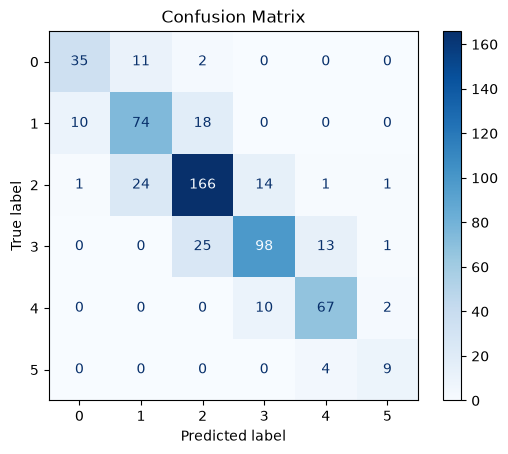

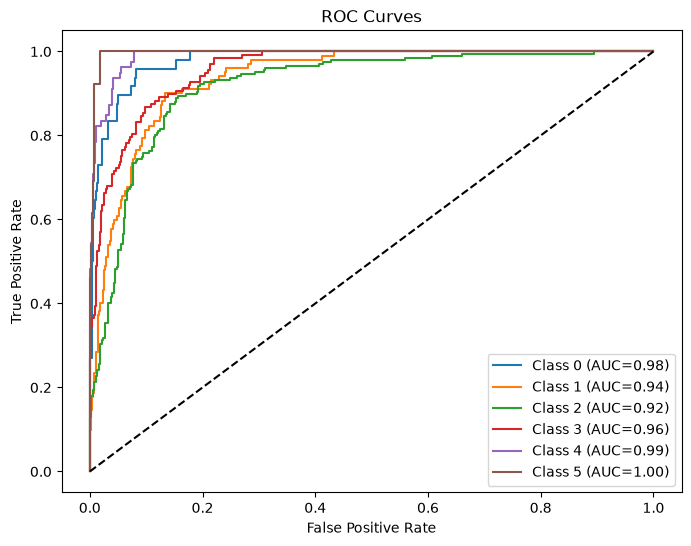

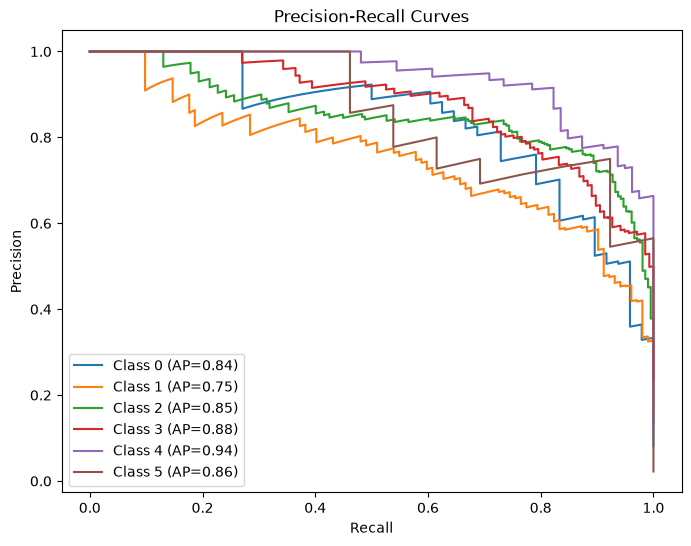

      clasa  precision  recall     f1  support
0     <100k      0.761   0.729  0.745       48
1  100-130k      0.679   0.725  0.701      102
2  130-180k      0.787   0.802  0.794      207
3  180-250k      0.803   0.715  0.757      137
4  250-400k      0.788   0.848  0.817       79
5    >=400k      0.692   0.692  0.692       13


In [5]:
best_params = dict(study.best_params)
use_weights = best_params.pop("sample_weight_balanced")   # scoatem ce nu e parametru XGBoost

model_final = metrics_eval.fit_xgb(X_train, y_train, preprocessor,
                        params=best_params, use_class_weight=use_weights, early_stopping=False)
res = metrics_eval.evaluate_model(model_final, X_test, y_test, show_plots=True)

Interpretarea rezultatelor pe test

Modelul optimizat obtine pe setul de test macro-F1 = 0.7511, accuracy = 0.7662, macro-precision = 0.7517 si macro-recall = 0.7521. Comparat cu modelul de baza din partea B (aceleasi date, acelasi split), toate metricile principale cresc:
- macro-F1: 0.7412 -> 0.7511 (+0.010)
- macro-recall: 0.7293 -> 0.7521 (+0.023)
- accuracy: 0.7628 -> 0.7662 (+0.003)
- Average Precision macro: 0.8423 -> 0.8529 (+0.011)

Castigul cel mai mare este la recall, iar explicatia este ca Optuna a ales ponderi echilibrate pe clase (sample_weight_balanced = True). Ponderile cresc importanta claselor mici la antrenare, deci modelul le recunoaste mai des. Se vede cel mai clar la clasa 5 (>=400k): recall 0.615 -> 0.692 si F1 0.667 -> 0.692. Pe clasele mari diferentele sunt mici, in ambele directii (clasa 3 scade usor, de la 0.766 la 0.757).

Pe CV, cel mai bun macro-F1 a fost 0.7765 ± 0.016, iar pe test 0.7511. Diferenta are doua cauze. Prima: am ales maximul dintre 50 de incercari, iar acest maxim este usor optimist, pentru ca o parte din avantajul lui vine din zgomotul foldurilor. A doua: testul este un singur split de 586 de case, iar clasa 5 are doar 13 case in test, deci o singura casa clasificata diferit schimba recall-ul clasei 5 cu aproape 0.08. Scorul de pe test este estimarea cinstita a performantei modelului.

Matricea de confuzie

Diagonala contine casele clasificate corect: 449 din 586. Aproape toate greselile sunt intre clase vecine: din cele 137 de case gresite, 131 sunt puse cu o clasa mai sus sau mai jos si doar 6 sar peste o clasa. Modelul a invatat deci corect ordinea preturilor, iar greselile sunt case aflate aproape de pragurile dintre clase (o casa de 128,000 si una de 132,000 sunt aproape identice, dar sunt in clase diferite). Cele mai multe confuzii sunt intre clasele 1 si 2 (24 + 18 case) si intre 2 si 3 (25 + 14), adica in zona 100,000-250,000, unde sunt cele mai multe case si cele mai mici diferente de pret intre clase.

Curbele ROC

Fiecare curba compara o clasa cu toate celelalte (one-vs-rest). Toate clasele au AUC peste 0.91, iar media macro este 0.9634. Clasele extreme se separa cel mai usor: clasa 0 (0.980), clasa 4 (0.990) si clasa 5 (0.996). Cel mai greu se separa clasele din mijloc, 2 (0.920) si 1 (0.938), pentru ca au vecini de ambele parti. Valoarea ROC-AUC este practic aceeasi ca la modelul de baza (0.9637): optimizarea nu a schimbat capacitatea modelului de a ordona casele dupa probabilitate, ci felul in care sunt luate deciziile, mai ales pentru clasele mici.

Curbele precision-recall

La clase dezechilibrate, curbele precision-recall sunt mai informative decat ROC, pentru ca nu sunt influentate de numarul mare de exemple negative. Average Precision (aria de sub curba) este cea mai mica la clasa 1 (0.753), clasa cu cele mai multe confuzii, si cea mai mare la clasa 4 (0.939). Clasa 5 are AP = 0.861, mult peste modelul de baza (0.823), ceea ce confirma ca ponderile pe clase au imbunatatit in special recunoasterea caselor scumpe.

In [ ]:
# Toate incercarile din studiu, ca tabel pandas
import optuna

study = optuna.load_study(
    study_name="xgboost_optimization",
    storage=f"sqlite:///{(ROOT / 'optuna_xgboost.db').as_posix()}",
)
trials_df = study.trials_dataframe()
display(trials_df.sort_values("value", ascending=False).head(10))

,number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_gamma,params_learning_rate,params_max_depth,params_min_child_weight,params_n_estimators,params_reg_lambda,params_sample_weight_balanced,params_subsample,user_attrs_cv_f1_std,system_attrs_tpe:relative_params:0,state
35,35,0.776486,2026-10-31 14:21:30.206581,2026-10-31 14:21:46.499495,0 days 00:00:16.292914,0.507107,0.417389,0.062637,7,1.335920,371,0.027179,True,0.720522,0.015867,"{""colsample_bytree"": 0.5071073082380428, ""gamm...",COMPLETE
18,18,0.774275,2026-10-31 13:55:19.654501,2026-10-31 13:55:33.889578,0 days 00:00:14.235077,0.466629,0.492368,0.080106,7,1.785536,287,0.065566,True,0.711575,0.019297,"{""colsample_bytree"": 0.46662932895972165, ""gam...",COMPLETE
43,43,0.773739,2026-10-31 14:23:38.659928,2026-10-31 14:23:58.057061,0 days 00:00:19.397133,0.428419,0.489444,0.064507,8,1.563055,461,0.021305,True,0.687435,0.011818,"{""colsample_bytree"": 0.42841860807075915, ""gam...",COMPLETE
26,26,0.772921,2026-10-31 13:56:53.671304,2026-10-31 13:57:11.082943,0 days 00:00:17.411639,0.438332,0.623098,0.058558,8,1.441852,320,0.151571,True,0.723251,0.018143,"{""colsample_bytree"": 0.4383316187595348, ""gamm...",COMPLETE
47,47,0.772376,2026-10-31 14:25:06.982700,2026-10-31 15:29:53.740987,0 days 01:04:46.758287,0.402877,0.679026,0.047945,7,1.165593,323,0.068106,True,0.730498,0.020255,"{""colsample_bytree"": 0.4028768920557086, ""gamm...",COMPLETE
46,46,0.772289,2026-10-31 14:24:44.311337,2026-10-31 14:25:06.947267,0 days 00:00:22.635930,0.568051,0.412720,0.050407,8,1.939254,308,0.055620,True,0.689821,0.015546,"{""colsample_bytree"": 0.5680505322395987, ""gamm...",COMPLETE
38,38,0.771667,2026-10-31 14:22:15.186996,2026-10-31 14:22:33.630694,0 days 00:00:18.443698,0.528643,0.295703,0.048856,7,1.713483,357,0.048944,True,0.736893,0.013025,"{""colsample_bytree"": 0.5286433619769668, ""gamm...",COMPLETE
34,34,0.771137,2026-10-31 14:21:16.567345,2026-10-31 14:21:30.185830,0 days 00:00:13.618485,0.582841,0.247289,0.105936,8,2.135108,310,0.021113,True,0.742273,0.016363,"{""colsample_bytree"": 0.582841167608987, ""gamma...",COMPLETE
44,44,0.770782,2026-10-31 14:23:58.079646,2026-10-31 14:24:23.466927,0 days 00:00:25.387281,0.499029,0.444316,0.054538,8,1.389045,540,0.026990,True,0.657218,0.014623,"{""colsample_bytree"": 0.4990291168210667, ""gamm...",COMPLETE
27,27,0.770587,2026-10-31 13:57:11.130646,2026-10-31 14:19:55.870187,0 days 00:22:44.739541,0.505155,0.439717,0.089362,7,1.564244,271,0.014484,True,0.746145,0.011230,"{""colsample_bytree"": 0.5051549134374981, ""gamm...",COMPLETE


Analiza incercarilor Optuna

Cele 50 de incercari au obtinut macro-F1 pe CV intre 0.7185 si 0.7765, cu mediana 0.7617. Cel mai bun rezultat (incercarea 35) este cu aproximativ 0.019 peste modelul de baza din partea B (0.7571).

TPESampler a invatat din incercarile anterioare: media primelor 10 incercari este 0.7427, iar a ultimelor 10 este 0.7697. Cel mai bun scor s-a imbunatatit in pasi (0.754 la incercarea 0, apoi 0.758, 0.760, 0.764, 0.774 la incercarea 18 si 0.7765 la incercarea 35), iar dupa incercarea 18 castigurile devin mici. Cautarea a ajuns deci intr-o zona stabila, iar mai multe incercari ar aduce probabil doar imbunatatiri sub deviatia standard dintre folduri (aproximativ 0.016).

Primele 10 incercari au valori foarte asemanatoare ale hiperparametrilor:
- sample_weight_balanced = True la toate 10 (si la 44 din 50 de incercari in total). Media macro-F1 cu ponderi este 0.763, fara ponderi 0.737. Este decizia cu cel mai mare efect.
- max_depth 7-8, adica arbori adanci. Cele 4 incercari cu max_depth de cel mult 3 au media 0.745.
- learning_rate 0.05-0.11 si n_estimators 271-540: pasi moderati cu un numar mediu de arbori.
- colsample_bytree 0.40-0.58 si subsample 0.66-0.75: fiecare arbore vede doar o parte din coloane si din case, ceea ce reduce corelatia dintre arbori.
- min_child_weight 1.2-2.1, gamma 0.25-0.68 si reg_lambda 0.01-0.15: regularizare slaba.

Combinatia este logica: arborii adanci, cu regularizare slaba, ar face overfitting singuri, dar esantionarea randurilor si coloanelor (subsample, colsample_bytree) si learning rate-ul moderat compenseaza. Rezultatul confirma concluzia partii B, ca valorile moderate de colsample_bytree si subsample sunt utile, si arata ca efectul important vine din combinatia parametrilor, pe care sweep-urile univariate din partea B nu o puteau surprinde.

Observatie: coloana duration arata pentru incercarile 27 si 47 durate de 22 de minute si o ora, desi celelalte incercari dureaza 14-25 de secunde. Aceste valori nu tin de model, ci de pauze in rularea calculatorului (de exemplu intrarea in sleep) in timpul incercarilor respective.